
# PROYECTO DE FORECASTING DE VENTAS RETAIL

## Introducción:
Este dataset contiene registros sintéticos de ventas diarias del sector retail desde enero de 2019 hasta diciembre de 2023. Su diseño busca replicar el comportamiento de la demanda en un entorno comercial real, considerando componentes temporales como tendencia, estacionalidad, cambios en los precios y campañas promocionales, lo que lo convierte en una fuente adecuada para el desarrollo y evaluación de modelos de forecasting.

## Objetivo:
Predecir las ventas futuras utilizando información histórica y variables externas como promociones y precios.

## Variables:
- sales -> variable objetivo
- date -> fecha
- promo -> promociones
- price -> precio
- weekday -> día de la semana
- month -> mes

## Técnicas a utilizar:
1. Análisis exploratorio
2. Ingeniería de características
3. Forecasting baseline
4. Random Forest
5. XGBoost
6. Comparación de métricas


In [81]:
# ==========================================================
# IMPORTACIÓN DE LIBRERÍAS
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
plt.rcParams['figure.figsize'] = (10,6)

# Configuración de decimales
pd.set_option('display.float_format', '{:.4f}'.format)

# warnigs se utiliza para controlar mensajes de advertencia
import warnings

# desactivar las advertencias para mantener la salida del notebook de manera limpia y consisa 
warnings.filterwarnings("ignore")


# ==========================================================
# MACHINE LEARNING
# ==========================================================

# XGBRegressor:
# Implementación del algoritmo XGBoost para problemas de regresión. 
# Es uno de los modelos más utilizados para forecasting debido a su alta capacidad predictiva.
from xgboost import XGBRegressor

from sklearn.ensemble import RandomForestRegressor

# ==========================================================
# MÉTRICAS DE EVALUACIÓN
# ==========================================================

# Mean Absolute Error (MAE):
# Promedio del error absoluto entre valores reales y predicciones.
from sklearn.metrics import mean_absolute_error

# Mean Squared Error (MSE): Penaliza más los errores grandes elevándolos al cuadrado.
from sklearn.metrics import mean_squared_error

# Mean Absolute Percentage Error (MAPE): Mide el error en términos porcentuales.
from sklearn.metrics import mean_absolute_percentage_error

# ==========================================================
# VALIDACIÓN TEMPORAL
# ==========================================================

# TimeSeriesSplit: Permite dividir datos temporales respetando el orden cronológico.

# A diferencia de train_test_split, no mezcla observaciones.

# Es la técnica recomendada para evaluar modelos de forecasting.
from sklearn.model_selection import TimeSeriesSplit

# Importar función para descomponer una serie temporal en:
# tendencia, estacionalidad y residuales.
from statsmodels.tsa.seasonal import seasonal_decompose

from statsmodels.tsa.statespace.sarimax import SARIMAX

# ========================================================
# CONFIGURACIÓN VISUAL DEL NOTEBOOK
# ==========================================================

# Muestra todas las columnas de un DataFrame
# sin truncarlas cuando se imprime en pantalla.
pd.set_option('display.max_columns', None)


In [143]:
# Cargar dataset
df_retail = pd.read_csv("retail_sales.csv")

# Visualizar primeras filas
display(df_retail)

,date,store_id,item_id,sales,price,promo,weekday,month
0,2019-01-01,store_1,item_1,41,21.3000,0,1,1
1,2019-01-02,store_1,item_1,53,21.3000,0,2,1
2,2019-01-03,store_1,item_1,39,21.3000,0,3,1
3,2019-01-04,store_1,item_1,35,21.3000,0,4,1
4,2019-01-05,store_1,item_1,51,17.0400,1,5,1
...,...,...,...,...,...,...,...,...
4564995,2023-12-27,store_50,item_50,28,64.1000,1,2,12
4564996,2023-12-28,store_50,item_50,15,80.1200,0,3,12
4564997,2023-12-29,store_50,item_50,12,80.1200,0,4,12
4564998,2023-12-30,store_50,item_50,11,80.1200,0,5,12


In [144]:
print("="*80)
print("INFORMACION GENERAL DEL DATASET")
print("="*80)

# Mostrar cantidad de filas y columnas
print(f"Registros(filas):{df_retail.shape[0]}")
print(f"Columnas: {df_retail.shape[1]}")

# Mostrar los tipos de datos 
print(f"\nTipos de datos:")
print(df_retail.dtypes)

INFORMACION GENERAL DEL DATASET
Registros(filas):4565000
Columnas: 8

Tipos de datos:
date         object
store_id     object
item_id      object
sales         int64
price       float64
promo         int64
weekday       int64
month         int64
dtype: object


In [84]:
# Mostrar las estadisticas basicas descriptivas
print("\nEstadisticas descriptivas:")
display(df_retail.describe())


Estadisticas descriptivas:


,sales,price,promo,weekday,month
count,4565000.0000,4565000.0000,4565000.0000,4565000.0000,4565000.0000
mean,29.2647,53.9932,0.1000,3.0016,6.5235
std,15.0100,25.7846,0.3000,1.9993,3.4485
min,0.0000,8.0200,0.0000,0.0000,1.0000
25%,18.0000,31.9700,0.0000,1.0000,4.0000
50%,27.0000,53.5200,0.0000,3.0000,7.0000
75%,38.0000,75.3600,0.0000,5.0000,10.0000
max,139.0000,99.9900,1.0000,6.0000,12.0000


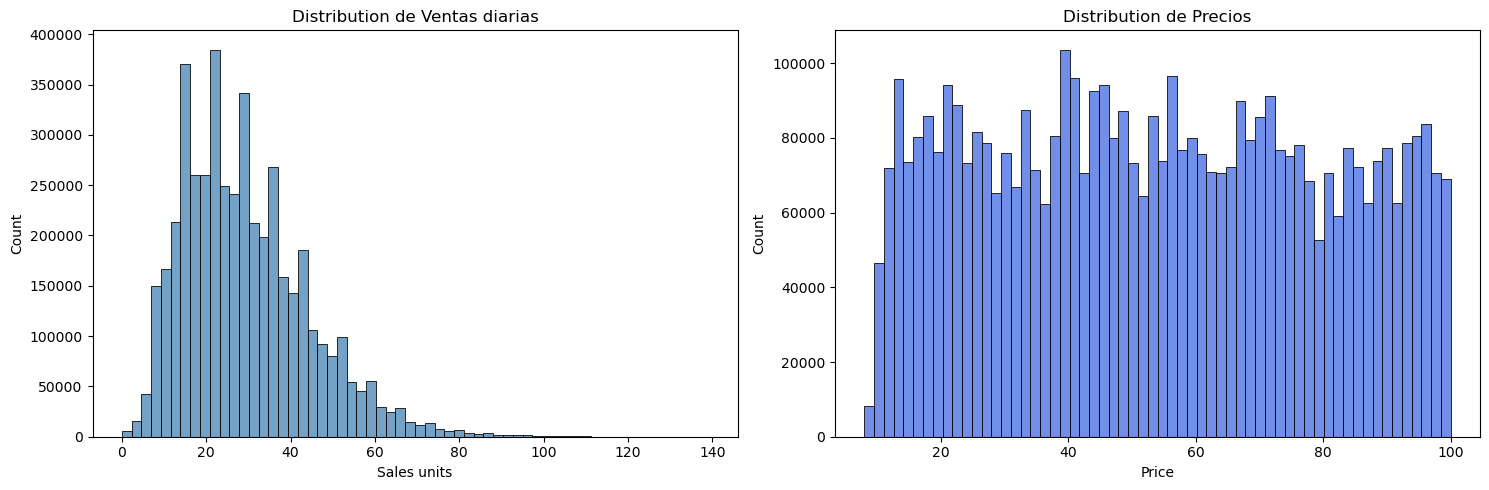

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df_retail["sales"], bins=60, color="steelblue", ax=axes[0])
axes[0].set_title("Distribution de Ventas diarias")
axes[0].set_xlabel("Sales units")
axes[0].set_ylabel("Count")

sns.histplot(df_retail["price"], bins=60, color="royalblue", ax=axes[1])
axes[1].set_title("Distribution de Precios")
axes[1].set_xlabel("Price")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

### Conversión de Fechas

Las fechas deben convertirse al formato datetime para poder extraer información temporal.

In [86]:
# Convertir fecha
df_retail["date"] = pd.to_datetime(df_retail["date"])

# Verificar
df_retail.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4565000 entries, 0 to 4564999
Data columns (total 8 columns):
 #   Column    Dtype         
---  ------    -----         
 0   date      datetime64[ns]
 1   store_id  object        
 2   item_id   object        
 3   sales     int64         
 4   price     float64       
 5   promo     int64         
 6   weekday   int64         
 7   month     int64         
dtypes: datetime64[ns](1), float64(1), int64(4), object(2)
memory usage: 278.6+ MB


In [87]:
# Contar valores nulos y calcular porcentaje de la columna.
valores_nulos = df_retail.isnull().sum()
porcentaje_nulos = (
    df_retail.isnull().sum()/len(df_retail))*100

# Crear el resumen de valores nulos
df_nulos = pd.DataFrame({
    "Valores_nulos": valores_nulos,
    "Porcentaje_%": porcentaje_nulos
})

display(df_nulos)

,Valores_nulos,Porcentaje_%
date,0,0.0000
store_id,0,0.0000
item_id,0,0.0000
sales,0,0.0000
price,0,0.0000
promo,0,0.0000
weekday,0,0.0000
month,0,0.0000


### Agregación Temporal

Técnica que consiste en resumir observaciones registradas a lo largo del tiempo en intervalos específicos. Esto permite transformar datos transaccionales en una serie temporal adecuada para el análisis y la predicción de ventas futuras.

***Como primer modelo vamos a predecir las ventas totales por día.***

In [88]:
# Agrupar ventas por fecha
ventas_diarias = (
    df_retail.groupby("date")
      .agg({
          "sales":"sum",
          "promo":"mean",
          "price":"mean"
      })
      .reset_index()
)

display(ventas_diarias)

,date,sales,promo,price
0,2019-01-01,74119,0.1004,53.9730
1,2019-01-02,77119,0.0976,53.9653
2,2019-01-03,70810,0.1080,53.8914
3,2019-01-04,59269,0.0932,54.0445
4,2019-01-05,52621,0.1028,53.9472
...,...,...,...,...
1821,2023-12-27,97603,0.1100,53.9377
1822,2023-12-28,88506,0.0944,54.0428
1823,2023-12-29,74957,0.0992,54.0026
1824,2023-12-30,66218,0.0976,53.9107


In [89]:
# Convertir a fecha
ventas_diarias['date'] = pd.to_datetime(
    ventas_diarias['date']
)

# Verificar
print(ventas_diarias.dtypes)

date     datetime64[ns]
sales             int64
promo           float64
price           float64
dtype: object


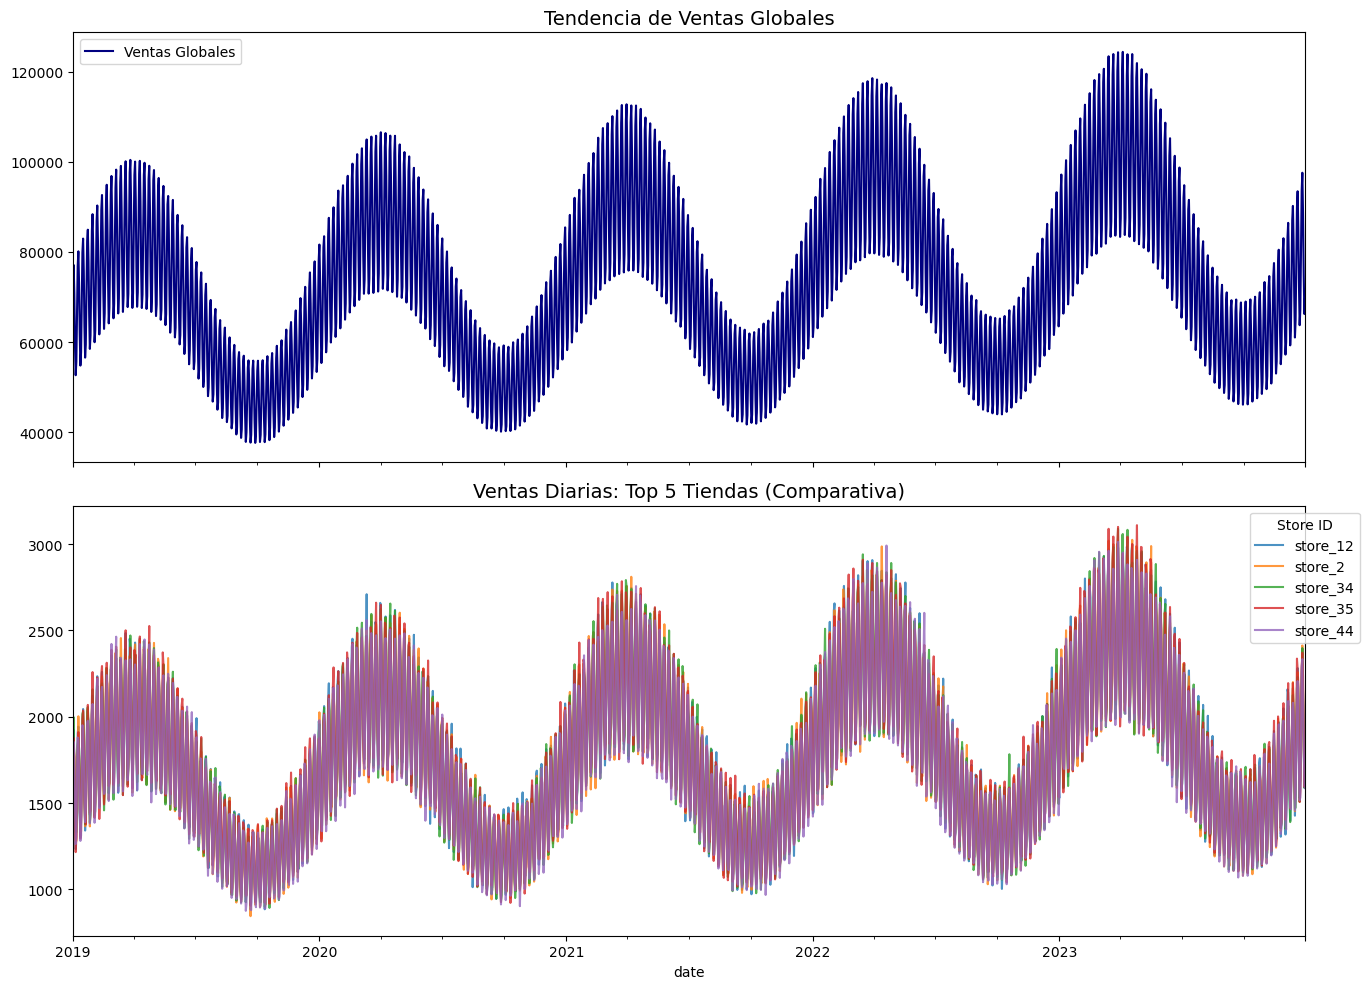

In [133]:
# 1.1 Agregación Global (Tendencia general)
global_sales = df_retail.groupby('date')['sales'].sum().reset_index()

# 1.2 Agregación por Tienda (Top 5 tiendas)
top_stores = df_retail.groupby('store_id')['sales'].sum().nlargest(5).index
store_sales = df_retail[df_retail['store_id'].isin(top_stores)].groupby(['date', 'store_id'])['sales'].sum().unstack()

# Visualización profesional
fig, ax = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

ax[0].plot(global_sales['date'], global_sales['sales'], color='navy', label='Ventas Globales')
ax[0].set_title('Tendencia de Ventas Globales', fontsize=14)
ax[0].legend()

store_sales.plot(ax=ax[1], alpha=0.8)
ax[1].set_title('Ventas Diarias: Top 5 Tiendas (Comparativa)', fontsize=14)
ax[1].legend(title='Store ID', bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

#### Visualización de la Serie Temporal

#### Tendencia

Identificamos si existe crecimiento o decrecimiento.

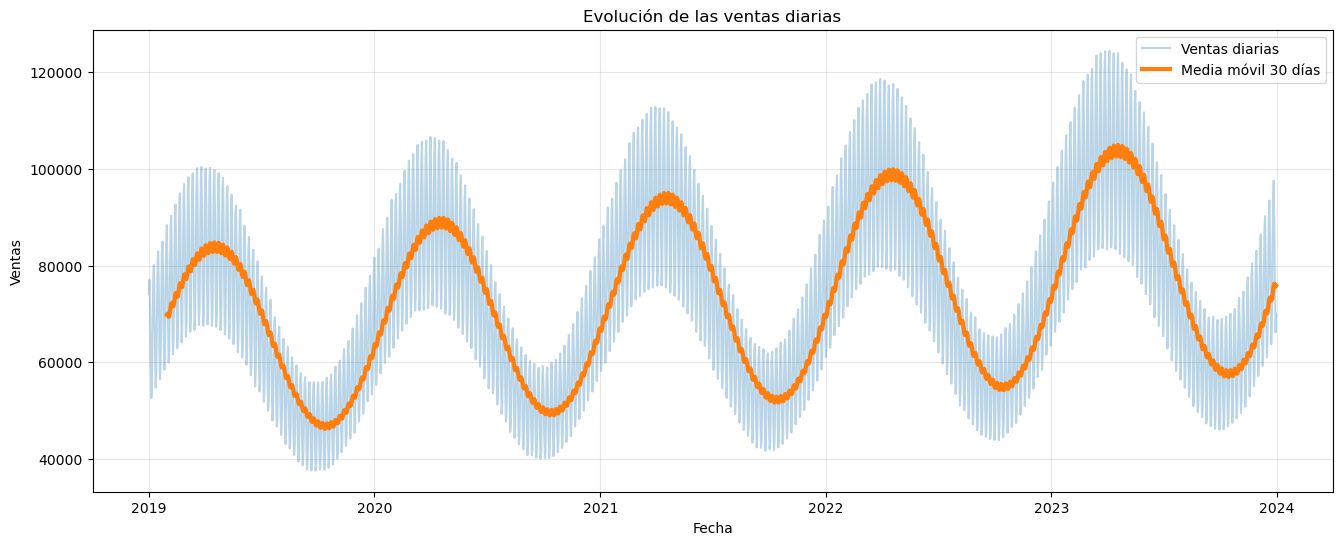

In [90]:
# Crear media móvil de 30 días
ventas_diarias['media_movil_30'] = (
    ventas_diarias['sales']
    .rolling(window=30)
    .mean()
)

# Graficar
plt.figure(figsize=(16,6))

plt.plot(
    ventas_diarias['date'],
    ventas_diarias['sales'],
    alpha=0.3,
    label='Ventas diarias'
)

plt.plot(
    ventas_diarias['date'],
    ventas_diarias['media_movil_30'],
    linewidth=3,
    label='Media móvil 30 días'
)

plt.title('Evolución de las ventas diarias')
plt.xlabel('Fecha')
plt.ylabel('Ventas')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

**Insight de Evolución Diaria**
- ***Alta Volatilidad a Corto Plazo:*** El volumen diario (línea azul clara) presenta oscilaciones constantes y pronunciadas, muy probablemente asociadas a un patrón de consumo semanal (como diferencias entre fines de semana y días laborables). Esto subraya la necesidad de una gestión operativa muy táctica para el abastecimiento del día a día.

- ***Tendencia Subyacente en Expansión:** Al aislar el "ruido" diario utilizando la media móvil de 30 días (línea naranja), se confirma un crecimiento estructural continuo que acompaña a la estacionalidad. Los picos cíclicos anuales han incrementado de forma sostenida, pasando de un promedio máximo de aproximadamente 80,000 ventas diarias en 2019 a superar la marca de las 100,000 en 2023, consolidando una clara trayectoria de expansión del negocio a largo plazo.

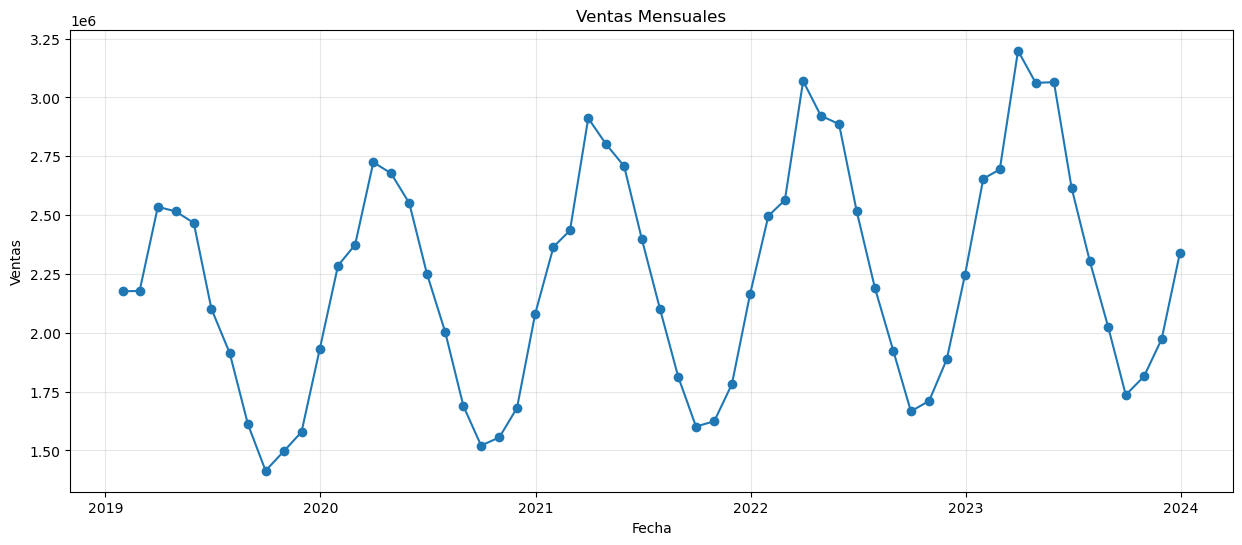

In [91]:
ventas_mensuales = (
    ventas_diarias
    .set_index('date')
    .resample('M')
    .sum()
    .reset_index()
)

plt.figure(figsize=(15,6))

plt.plot(
    ventas_mensuales['date'],
    ventas_mensuales['sales'],
    marker='o'
)

plt.title('Ventas Mensuales')
plt.xlabel('Fecha')
plt.ylabel('Ventas')

plt.grid(alpha=0.3)

plt.show()

**Insight de Rendimiento Comercial**
- ***Estacionalidad Predictible:*** El volumen de ventas presenta un patrón cíclico anual altamente marcado y repetitivo, lo cual es ideal para anticipar periodos de alta o baja demanda, optimizar niveles de inventario y proyectar el flujo de caja operativo.

- ***Crecimiento Interanual Sostenido:*** Más allá de las caídas estacionales esperadas, la trayectoria a largo plazo es netamente positiva. Los picos de máxima demanda han escalado de forma constante año tras año, pasando de un tope aproximado de 2.5 millones en 2019 a superar la barrera de los 3.0 millones en 2023.

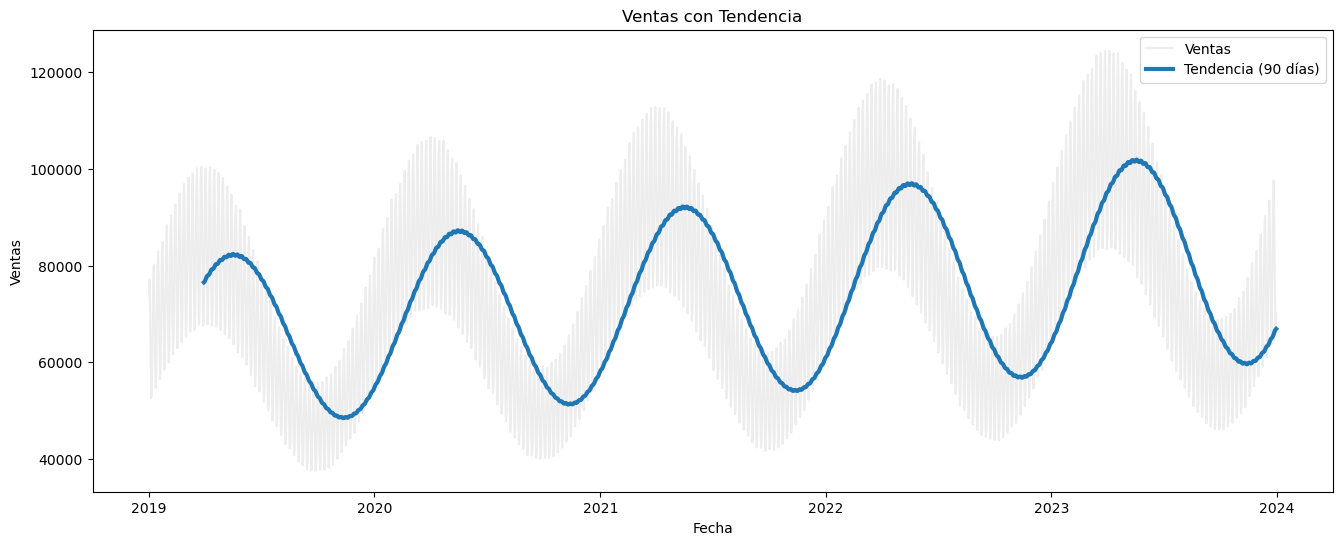

In [92]:
plt.figure(figsize=(16,6))

plt.plot(
    ventas_diarias['date'],
    ventas_diarias['sales'],
    color='lightgray',
    alpha=0.4,
    label='Ventas'
)

plt.plot(
    ventas_diarias['date'],
    ventas_diarias['sales'].rolling(90).mean(),
    linewidth=3,
    label='Tendencia (90 días)'
)

plt.legend()

plt.title('Ventas con Tendencia')
plt.xlabel('Fecha')
plt.ylabel('Ventas')

plt.show()

**Insight de Tendencia Trimestral**
- ***Visión Estratégica Purificada:*** Al implementar un filtro de tendencia de 90 días (línea azul), se elimina por completo el "ruido" de la volatilidad diaria y semanal. Esto permite aislar la verdadera inercia comercial del negocio, facilitando la planeación macro, la asignación de presupuestos trimestrales y la gestión de capacidad a mediano plazo.

- ***Elevación Estructural del Suelo Comercial:*** El gráfico confirma un crecimiento sumamente sólido y predecible, visible no solo en los picos, sino de manera crítica en los valles. Los niveles mínimos de venta anual (los suelos del negocio) se han elevado de forma constante, pasando de aproximadamente 59,000 unidades/ventas en el mínimo de 2019 a sostenerse sobre las 60,000 a finales de 2023, lo que demuestra una expansión orgánica y resiliente de la base de clientes o demanda mínima.

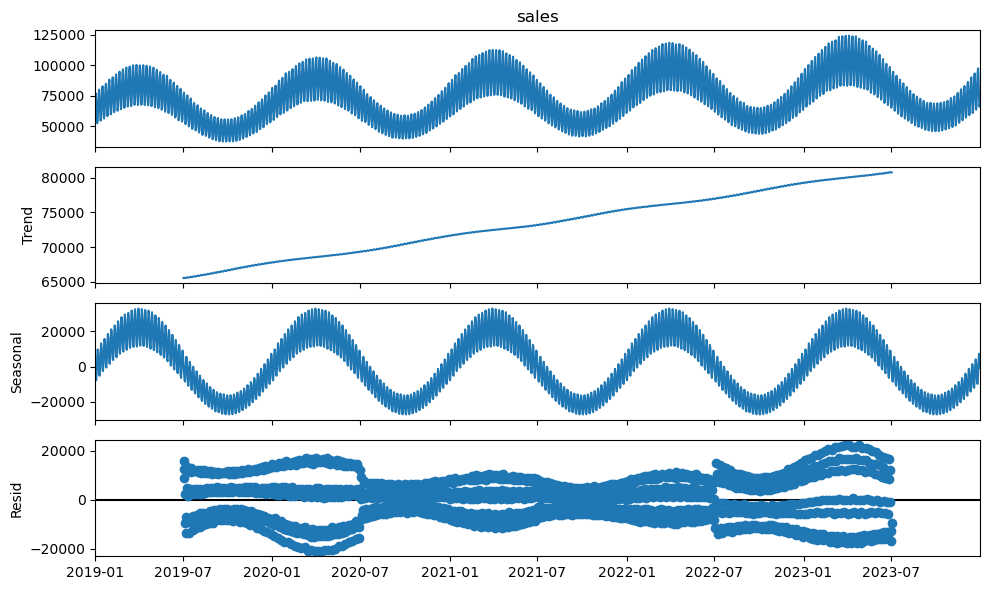

In [93]:

serie = ventas_diarias.set_index('date')['sales']

resultado = seasonal_decompose(
    serie,
    model='additive',
    period=365
)

resultado.plot()
plt.show()

**Insight de Descomposición de Series Temporales**
- ***Tracción Estructural Continua (Tendencia):*** Al aislar los factores cíclicos, el componente de tendencia (Trend) revela un crecimiento orgánico sumamente firme y lineal. El negocio ha incrementado su volumen base de ventas de manera sostenida, avanzando desde las 65,000 unidades a mediados de 2019 hasta superar las 80,000 a mediados de 2023, lo que demuestra la solidez del negocio a largo plazo.

- ***Anomalías Sistemáticas en Residuos (Resid):*** Aunque el componente estacional (Seasonal) captura perfectamente la oscilación anual repetitiva, el gráfico de residuos no muestra un "ruido blanco" puramente aleatorio. La presencia de patrones estructurados en forma de "bandas" (muy marcadas entre 2019-2020 y a partir de 2022) sugiere que existen variables externas o efectos de calendario específicos (como días festivos móviles o dinámicas promocionales agresivas) que el modelo de descomposición actual aún no ha logrado absorber por completo.

#### Ingeniería de Características

Los modelos predictivos no entienden fechas. Debemos convertir el tiempo en variables numéricas.

In [94]:
# Año
ventas_diarias["year"] = ventas_diarias["date"].dt.year

# Mes
ventas_diarias["month"] = ventas_diarias["date"].dt.month

# Día del mes
ventas_diarias["day"] = ventas_diarias["date"].dt.day

# Día semana
ventas_diarias["weekday"] = ventas_diarias["date"].dt.weekday

# Trimestre
ventas_diarias["quarter"] = ventas_diarias["date"].dt.quarter

# Fin de semana
ventas_diarias["weekend"] = (
    ventas_diarias["weekday"] >= 5
).astype(int)

In [95]:
display(ventas_diarias)

,date,sales,promo,price,media_movil_30,year,month,day,weekday,quarter,weekend
0,2019-01-01,74119,0.1004,53.9730,NaN,2019,1,1,1,1,0
1,2019-01-02,77119,0.0976,53.9653,NaN,2019,1,2,2,1,0
2,2019-01-03,70810,0.1080,53.8914,NaN,2019,1,3,3,1,0
3,2019-01-04,59269,0.0932,54.0445,NaN,2019,1,4,4,1,0
4,2019-01-05,52621,0.1028,53.9472,NaN,2019,1,5,5,1,1
...,...,...,...,...,...,...,...,...,...,...,...
1821,2023-12-27,97603,0.1100,53.9377,75984.4333,2023,12,27,2,4,0
1822,2023-12-28,88506,0.0944,54.0428,76258.8333,2023,12,28,3,4,0
1823,2023-12-29,74957,0.0992,54.0026,75989.0667,2023,12,29,4,4,0
1824,2023-12-30,66218,0.0976,53.9107,75662.6333,2023,12,30,5,4,1


### Variables lag:
Las variables lag (o variables rezagadas) son valores pasados de la variable que queremos predecir. 

Se utilizan porque, en muchas series temporales, el comportamiento pasado influye en el comportamiento futuro.

Representan valores históricos de la variable objetivo.
Permiten incorporar información del pasado para que el modelo
identifican patrones temporales y mejoran la precisión de las predicciones.

In [96]:
# Ventas del día anterior
ventas_diarias["lag_1"] = ventas_diarias["sales"].shift(1)

# Ventas hace 7 días
ventas_diarias["lag_7"] = ventas_diarias["sales"].shift(7)

# Ventas hace 30 días
ventas_diarias["lag_30"] = ventas_diarias["sales"].shift(30)

In [97]:
display(ventas_diarias)


,date,sales,promo,price,media_movil_30,year,month,day,weekday,quarter,weekend,lag_1,lag_7,lag_30
0,2019-01-01,74119,0.1004,53.9730,NaN,2019,1,1,1,1,0,NaN,NaN,NaN
1,2019-01-02,77119,0.0976,53.9653,NaN,2019,1,2,2,1,0,74119.0000,NaN,NaN
2,2019-01-03,70810,0.1080,53.8914,NaN,2019,1,3,3,1,0,77119.0000,NaN,NaN
3,2019-01-04,59269,0.0932,54.0445,NaN,2019,1,4,4,1,0,70810.0000,NaN,NaN
4,2019-01-05,52621,0.1028,53.9472,NaN,2019,1,5,5,1,1,59269.0000,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1821,2023-12-27,97603,0.1100,53.9377,75984.4333,2023,12,27,2,4,0,93568.0000,93491.0000,68539.0000
1822,2023-12-28,88506,0.0944,54.0428,76258.8333,2023,12,28,3,4,0,97603.0000,85338.0000,80274.0000
1823,2023-12-29,74957,0.0992,54.0026,75989.0667,2023,12,29,4,4,0,88506.0000,72341.0000,83050.0000
1824,2023-12-30,66218,0.0976,53.9107,75662.6333,2023,12,30,5,4,1,74957.0000,63737.0000,76011.0000


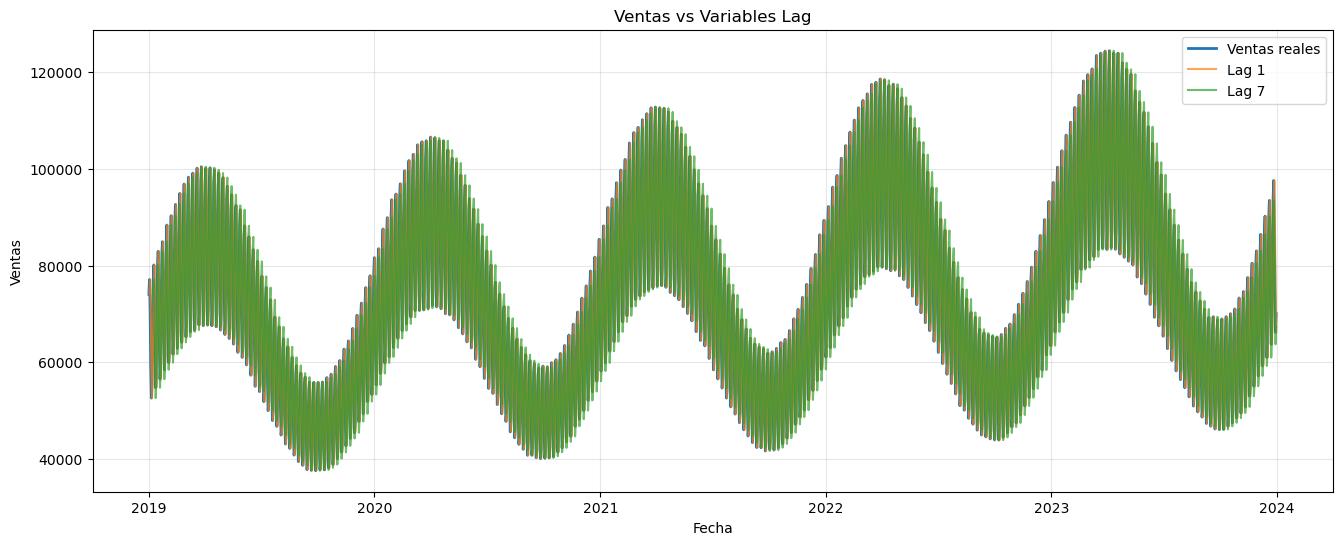

In [98]:
plt.figure(figsize=(16,6))

plt.plot(
    ventas_diarias['date'],
    ventas_diarias['sales'],
    label='Ventas reales',
    linewidth=2
)

plt.plot(
    ventas_diarias['date'],
    ventas_diarias['lag_1'],
    alpha=0.7,
    label='Lag 1'
)

plt.plot(
    ventas_diarias['date'],
    ventas_diarias['lag_7'],
    alpha=0.7,
    label='Lag 7'
)

plt.title('Ventas vs Variables Lag')
plt.xlabel('Fecha')
plt.ylabel('Ventas')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

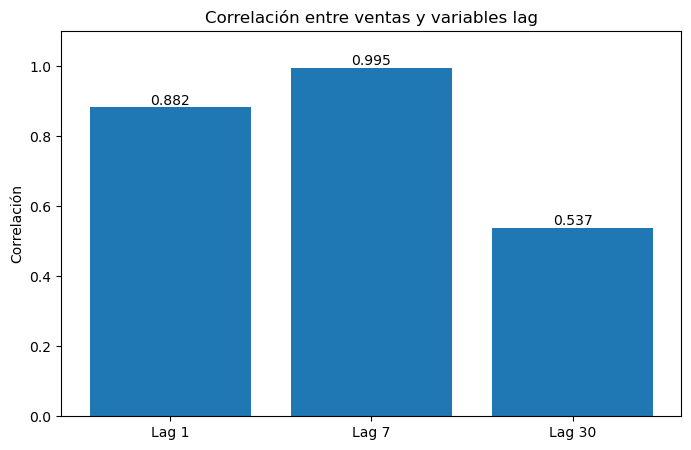

In [99]:
plt.figure(figsize=(8,5))

correlaciones = [
    ventas_diarias['sales'].corr(ventas_diarias['lag_1']),
    ventas_diarias['sales'].corr(ventas_diarias['lag_7']),
    ventas_diarias['sales'].corr(ventas_diarias['lag_30'])
]

barras = plt.bar(
    ['Lag 1','Lag 7','Lag 30'],
    correlaciones
)

# Mostrar valor encima de cada barra
for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width()/2,
        altura,
        f'{altura:.3f}',
        ha='center',
        va='bottom'
    )

plt.title('Correlación entre ventas y variables lag')
plt.ylabel('Correlación')
plt.ylim(0,1.1)

plt.show()

La variable `lag_7` presenta la mayor correlación con las ventas actuales, lo que evidencia una fuerte estacionalidad semanal. Esto indica que el comportamiento de las ventas tiende a repetirse cada siete días, convirtiendo a esta variable en una de las características más relevantes para el modelo de forecasting.

In [100]:
print(ventas_diarias.shape)

(1826, 14)


**Insight de Variables Lag:**

Las variables rezagadas (lags) y las medias móviles generan valores nulos al inicio de la serie debido a la ausencia de observaciones históricas suficientes. Este comportamiento es esperado en procesos de ingeniería de características para series temporales y debe gestionarse antes del entrenamiento del modelo.

In [101]:
# Antes de entrenar el modelo, es necesario eliminar las filas con valores nulos generados 
# por lags y rolling.

ventas_diarias = ventas_diarias.dropna()

# Verificar dimensiones
print(ventas_diarias.shape)

(1796, 14)


### Rolling Features

Variables que resumen el comportamiento reciente de la serie mediante una ventana móvil de observaciones históricas.

Permiten capturar tendencias de corto y mediano plazo, reduciendo el ruido presente en los valores diarios.

In [102]:
# Promedio últimos 7 días
ventas_diarias["rolling_mean_7"] = (
    ventas_diarias["sales"]
    .shift(1)
    .rolling(7)
    .mean()
)

# Promedio últimos 30 días
ventas_diarias["rolling_mean_30"] = (
    ventas_diarias["sales"]
    .shift(1)
    .rolling(30)
    .mean()
)

Mientras las variables lag permiten conocer valores específicos del pasado, las rolling features proporcionan una visión más estable de la evolución reciente de las ventas. Estas características suelen mejorar significativamente el desempeño de los modelos de forecasting al capturar tendencias y suavizar fluctuaciones temporales.

In [103]:
display(ventas_diarias)

,date,sales,promo,price,media_movil_30,year,month,day,weekday,quarter,weekend,lag_1,lag_7,lag_30,rolling_mean_7,rolling_mean_30
30,2019-01-31,80590,0.0968,54.0228,70074.9333,2019,1,31,3,1,0,88401.0000,77981.0000,74119.0000,NaN,NaN
31,2019-02-01,67776,0.0992,53.9587,69763.5000,2019,2,1,4,1,0,80590.0000,66083.0000,77119.0000,NaN,NaN
32,2019-02-02,59952,0.0992,53.9804,69401.5667,2019,2,2,5,1,1,67776.0000,58469.0000,70810.0000,NaN,NaN
33,2019-02-03,62549,0.0948,54.0864,69510.9000,2019,2,3,6,1,1,59952.0000,61461.0000,59269.0000,NaN,NaN
34,2019-02-04,75624,0.1076,53.9342,70277.6667,2019,2,4,0,1,0,62549.0000,72812.0000,52621.0000,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1821,2023-12-27,97603,0.1100,53.9377,75984.4333,2023,12,27,2,4,0,93568.0000,93491.0000,68539.0000,79444.7143,75015.6333
1822,2023-12-28,88506,0.0944,54.0428,76258.8333,2023,12,28,3,4,0,97603.0000,85338.0000,80274.0000,80032.1429,75984.4333
1823,2023-12-29,74957,0.0992,54.0026,75989.0667,2023,12,29,4,4,0,88506.0000,72341.0000,83050.0000,80484.7143,76258.8333
1824,2023-12-30,66218,0.0976,53.9107,75662.6333,2023,12,30,5,4,1,74957.0000,63737.0000,76011.0000,80858.4286,75989.0667


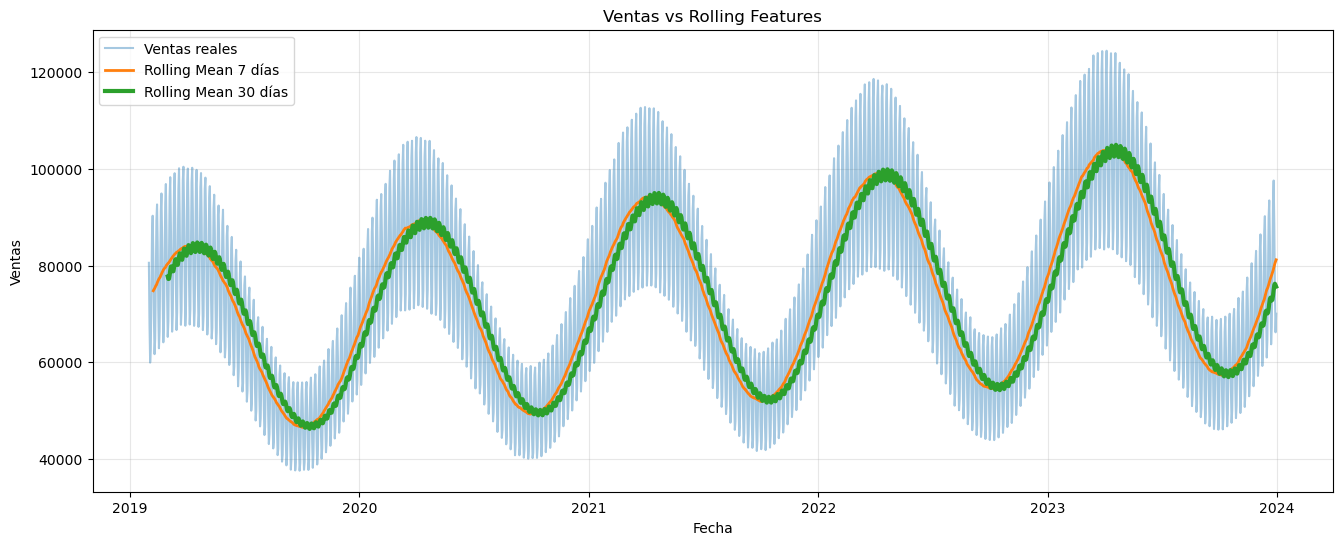

In [104]:
# Crear gráfico
plt.figure(figsize=(16,6))

# Ventas reales
plt.plot(
    ventas_diarias['date'],
    ventas_diarias['sales'],
    alpha=0.4,
    label='Ventas reales'
)

# Media móvil 7 días
plt.plot(
    ventas_diarias['date'],
    ventas_diarias['rolling_mean_7'],
    linewidth=2,
    label='Rolling Mean 7 días'
)

# Media móvil 30 días
plt.plot(
    ventas_diarias['date'],
    ventas_diarias['rolling_mean_30'],
    linewidth=3,
    label='Rolling Mean 30 días'
)

plt.title('Ventas vs Rolling Features')
plt.xlabel('Fecha')
plt.ylabel('Ventas')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [105]:
ventas_diarias = ventas_diarias.dropna()

ventas_diarias.shape

(1766, 16)

### División Train-Test

En series temporales nunca se mezclan fechas.

In [106]:
# Últimos 90 días para prueba

train = ventas_diarias.iloc[:-90]
test = ventas_diarias.iloc[-90:]


### Modelo Baseline

La predicción del mañana será igual a hoy.

Sirve como referencia mínima.

In [107]:
test["baseline"] = test["lag_1"]

mae_baseline = mean_absolute_error(
    test["sales"],
    test["baseline"]
)

print(mae_baseline)

7515.577777777778


***Test de Estacionariedad***
Es una prueba estadística que determina si las propiedades de una serie de tiempo (como su media y su varianza) son constantes a lo largo del tiempo.

En términos prácticos, sirve para saber si los datos tienen una tendencia que debe ser eliminada (como ventas que siempre suben) o si ya son estables, lo cual es un requisito obligatorio para que modelos como SARIMA funcionen correctamente sin sesgarse.

In [134]:
from statsmodels.tsa.stattools import adfuller

def check_stationarity(series):
    result = adfuller(series.values)
    print(f'ADF Statistic: {result[0]:.4f}')
    print(f'p-value: {result[1]:.4f}')
    print('Críticos:')
    for key, value in result[4].items():
        print(f'\t{key}: {value:.4f}')
    
    if result[1] <= 0.05:
        print("\nResultado: La serie es ESTACIONARIA (Rechazamos H0)")
    else:
        print("\nResultado: La serie NO es estacionaria (No rechazamos H0). Se recomienda diferenciar.")

# Aplicar a las ventas globales
print("--- Test de Estacionariedad para Ventas Globales ---")
check_stationarity(global_sales['sales'])

--- Test de Estacionariedad para Ventas Globales ---
ADF Statistic: -12.1800
p-value: 0.0000
Críticos:
	1%: -3.4340
	5%: -2.8631
	10%: -2.5676

Resultado: La serie es ESTACIONARIA (Rechazamos H0)


Prueba de Estacionariedad (ADF Test):

Resultado: 

El estadístico ADF (-12.18) es significativamente menor que los valores críticos, y el p-value (0.0000) es inferior a 0.05.

Conclusión Técnica: Rechazamos la hipótesis nula ($H_0$); la serie de ventas globales es estacionaria.

Impacto en SARIMA: No es necesario aplicar diferenciación de primer orden para estabilizar la media. Por lo tanto, el parámetro de integración del modelo será $d=0$. El modelo se centrará directamente en capturar los componentes AR (autorregresivos), MA (medias móviles) y la estacionalidad (S).

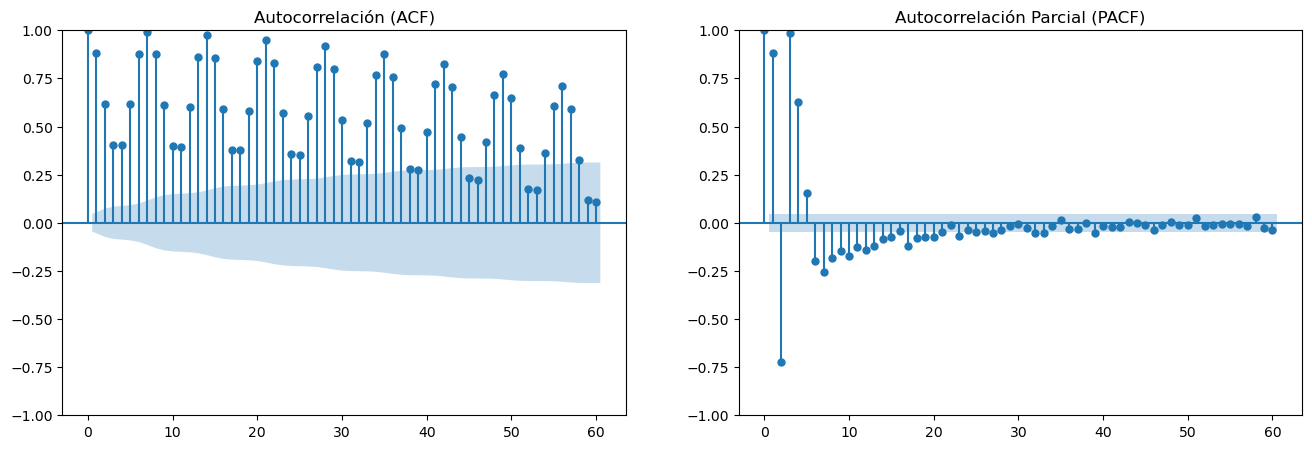

In [135]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# ACF: Detecta estacionalidad (picos en 7, 14, 30 días)
plot_acf(global_sales['sales'], lags=60, ax=ax1, title='Autocorrelación (ACF)')

# PACF: Identifica el orden del proceso Autorregresivo (AR)
plot_pacf(global_sales['sales'], lags=60, ax=ax2, title='Autocorrelación Parcial (PACF)')

plt.show()

**Análisis de Autocorrelación (ACF/PACF):**

***Ayuda a definir cuántos periodos anteriores (lags) debe "mirar" un modelo para predecir con precisión el valor de hoy.***

***Periodicidad:*** Se observan picos significativos y repetitivos cada 7 lags en ambos gráficos. Esto confirma una estacionalidad semanal fuerte en el comportamiento de las ventas.

***Componente AR (PACF):*** Los primeros lags (1 y 2) son muy significativos, lo que sugiere un orden autorregresivo inicial de $p=1$ o $p=2$.

***Componente MA (ACF):*** El decaimiento lento en el ACF refuerza la necesidad de un componente de media móvil o una estructura estacional marcada.Decisión para SARIMA: Dado el patrón en el lag 7, el modelo debe configurarse con un componente estacional de $S=7$. Los parámetros base sugeridos para iterar son $(1, 0, 1) \times (1, 0, 1)_7$.

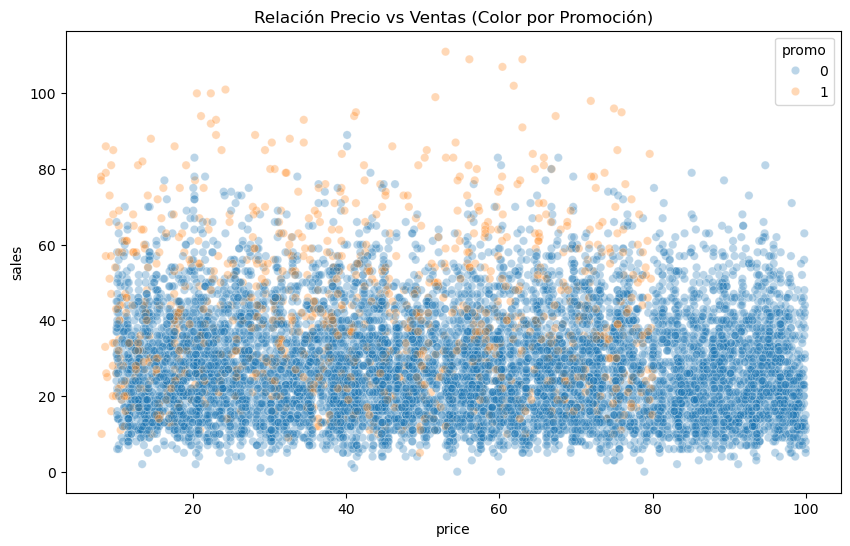

Elasticidad Precio de la Demanda: -0.0472
Interpretación: Un aumento del 1% en el precio reduce las ventas en un 0.05%


In [140]:
import statsmodels.api as sm

# 4.1 Visualización: Relación Precio vs Ventas
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_retail.sample(10000), x='price', y='sales', hue='promo', alpha=0.3)
plt.title('Relación Precio vs Ventas (Color por Promoción)')
plt.show()

# 4.2 Cálculo de Elasticidad mediante Log-Log Regression
# log(Sales) = β0 + β1 * log(Price) + ε -> β1 es la elasticidad
df_elasticity = df_retail[df_retail['sales'] > 0].copy()
df_elasticity['log_sales'] = np.log(df_elasticity['sales'])
df_elasticity['log_price'] = np.log(df_elasticity['price'])

X = sm.add_constant(df_elasticity['log_price'])
model = sm.OLS(df_elasticity['log_sales'], X).fit()

elasticity = model.params['log_price']
print(f"Elasticidad Precio de la Demanda: {elasticity:.4f}")
print(f"Interpretación: Un aumento del 1% en el precio reduce las ventas en un {abs(elasticity):.2f}%")

Análisis de Elasticidad Precio:

Coeficiente: $-0.0472$

Interpretación: La demanda es inelástica. Un aumento del 1% en el precio apenas reduce las ventas en un 0.05%.

Insight de Negocio: Esto sugiere que los productos en este dataset son de primera necesidad o tienen una fidelidad de marca alta, ya que los cambios en el precio no afectan drásticamente el volumen de ventas. Para el modelo de forecasting, esto significa que las variables de calendario y estacionalidad (lags) probablemente tengan más peso predictivo que las fluctuaciones de precio.

### Modelo SARIMA

In [136]:
modelo_sarima = SARIMAX(
    train["sales"],
    order=(1, 0, 1),           # Cambiamos d=1 a d=0 por estacionariedad
    seasonal_order=(1, 0, 1, 7),# Cambiamos D=1 a D=0 
    enforce_stationarity=False,
    enforce_invertibility=False
)

resultado = modelo_sarima.fit(disp=False)

In [137]:
pred_sarima = resultado.forecast(
    steps=len(test)
)

In [138]:
mae_sarima = mean_absolute_error(
    test["sales"],
    pred_sarima
)

rmse_sarima = np.sqrt(
    mean_squared_error(
        test["sales"],
        pred_sarima
    )
)

mape_sarima = mean_absolute_percentage_error(
    test["sales"],
    pred_sarima
)

print(f"MAE SARIMA: {mae_sarima:.4f}")
print(f"RMSE SARIMA: {rmse_sarima:.4f}")
print(f"MAPE SARIMA: {mape_sarima:.2%}")

MAE SARIMA: 10281.5928
RMSE SARIMA: 13281.3910
MAPE SARIMA: 14.24%


### Modelo XGBoost

In [111]:

# Variables predictoras
features = [
    'promo',
    'price',
    'rolling_mean_30',   # media de los 30 días ANTERIORES (sin incluir el día a predecir)
    'year',
    'month',
    'day',
    'weekday',
    'quarter',
    'weekend',
    'lag_1',
    'lag_7',
    'lag_30'
]

# Eliminar registros con valores nulos
df_modelo = ventas_diarias.dropna().copy()

# División temporal
train = df_modelo.iloc[:-90]
test = df_modelo.iloc[-90:]

# Variables independientes
X_train = train[features]
X_test = test[features]

# Variable objetivo
y_train = train['sales']
y_test = test['sales']

In [112]:
modelo_xgb = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    random_state=42
)

modelo_xgb.fit(
    X_train,
    y_train
)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [113]:
pred_xgb = modelo_xgb.predict(X_test)

In [114]:
mae = mean_absolute_error(
    y_test,
    pred_xgb
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        pred_xgb
    )
)

mape = mean_absolute_percentage_error(
    y_test,
    pred_xgb
)

print(f"MAE XGBoost: {mae:.4f}")
print(f"RMSE XGBoost: {rmse:.4f}")  
print(f"MAPE XGBoost: {mape:.2%}")

MAE XGBoost: 585.3776
RMSE XGBoost: 1044.4458
MAPE XGBoost: 0.80%


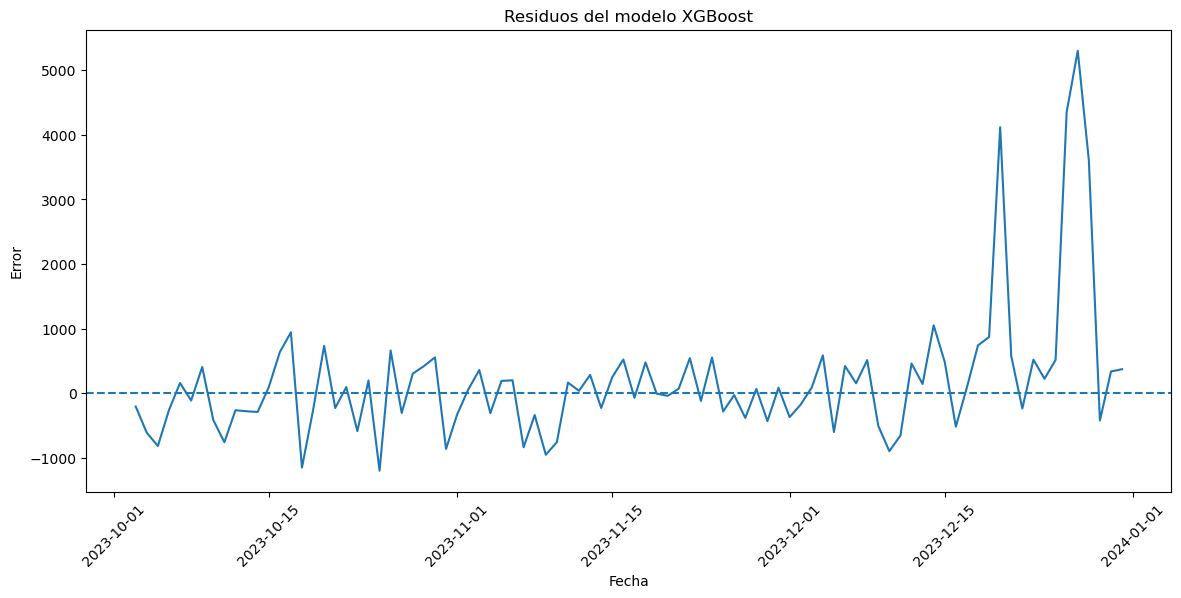

In [115]:
errores_xgb = test["sales"] - pred_xgb

plt.figure(figsize=(14,6))

plt.plot(
    test["date"],
    errores_xgb
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Residuos del modelo XGBoost")
plt.xlabel("Fecha")
plt.ylabel("Error")

plt.xticks(rotation=45)

plt.show()

In [116]:
modelo_rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)

pred_rf = modelo_rf.predict(X_test)

In [117]:
mae_rf = mean_absolute_error(y_test, pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, pred_rf))
mape_rf = mean_absolute_percentage_error(y_test, pred_rf)

print(f"MAE RANDOM FOREST: {mae_rf:,.4f}")
print(f"RMSE RANDOM FOREST: {rmse_rf:,.4f}")
print(f"MAPE RANDOM FOREST: {mape_rf:.2%}")

MAE RANDOM FOREST: 697.4940
RMSE RANDOM FOREST: 1,168.9959
MAPE RANDOM FOREST: 0.95%


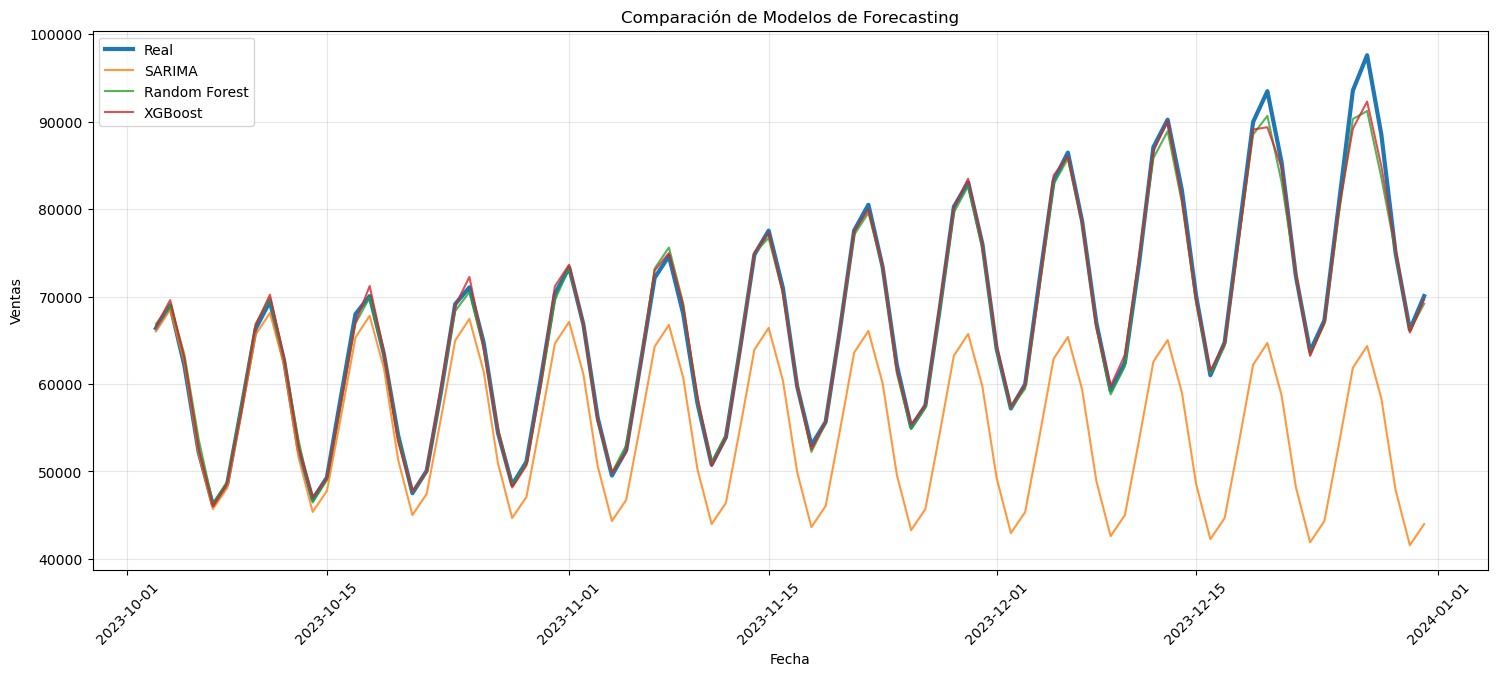

In [118]:
plt.figure(figsize=(18,7))

plt.plot(
    test["date"],
    test["sales"],
    label="Real",
    linewidth=3
)

plt.plot(
    test["date"],
    pred_sarima,
    label="SARIMA",
    alpha=0.8
)

plt.plot(
    test["date"],
    pred_rf,
    label="Random Forest",
    alpha=0.8
)

plt.plot(
    test["date"],
    pred_xgb,
    label="XGBoost",
    alpha=0.8
)

plt.title("Comparación de Modelos de Forecasting")
plt.xlabel("Fecha")
plt.ylabel("Ventas")

plt.legend()
plt.grid(alpha=0.3)

plt.xticks(rotation=45)

plt.show()

In [139]:
# ==========================================================
# TABLA COMPARATIVA DE MODELOS
# ==========================================================

resultados = pd.DataFrame({
    'Modelo': ['Baseline', 'SARIMA', 'Random Forest', 'XGBoost'],
    'MAE': [7515.5778, 10281.5928, 697.4940, 585.3776],
    'RMSE': [np.nan, 13281.3910, 1168.9959, 1044.4458],
    'MAPE (%)': [np.nan, 14.24, 0.95, 0.80]
})

resultados.sort_values('MAE')

,Modelo,MAE,RMSE,MAPE (%)
3,XGBoost,585.3776,1044.4458,0.8000
2,Random Forest,697.4940,1168.9959,0.9500
0,Baseline,7515.5778,NaN,NaN
1,SARIMA,10281.5928,13281.3910,14.2400


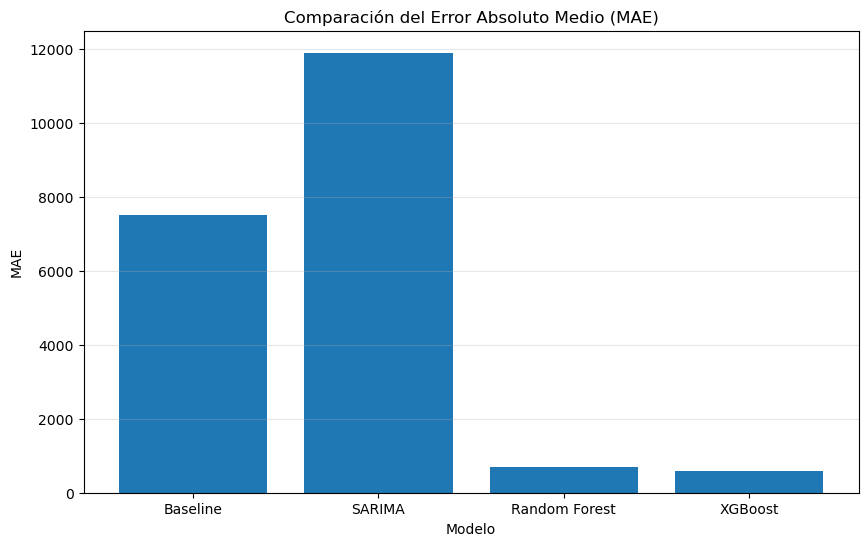

In [120]:
# ==========================================================
# COMPARACIÓN DE MAE ENTRE MODELOS
# ==========================================================

plt.figure(figsize=(10,6))

plt.bar(
    resultados['Modelo'],
    resultados['MAE']
)

plt.title('Comparación del Error Absoluto Medio (MAE)')
plt.xlabel('Modelo')
plt.ylabel('MAE')

plt.grid(axis='y', alpha=0.3)

plt.show()

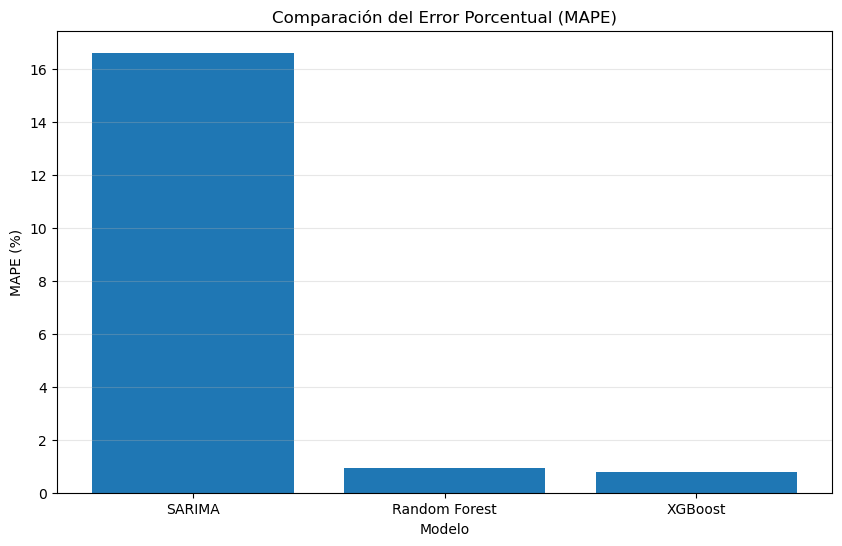

In [121]:
plt.figure(figsize=(10,6))

modelos_ml = resultados.dropna()

plt.bar(
    modelos_ml['Modelo'],
    modelos_ml['MAPE (%)']
)

plt.title('Comparación del Error Porcentual (MAPE)')
plt.xlabel('Modelo')
plt.ylabel('MAPE (%)')

plt.grid(axis='y', alpha=0.3)

plt.show()

In [122]:
importancias = pd.DataFrame({
    "Variable":features,
    "Importancia":modelo_xgb.feature_importances_
})

importancias = (
    importancias
    .sort_values(
        "Importancia",
        ascending=False
    )
)

importancias

,Variable,Importancia
10,lag_7,0.9921
4,month,0.0068
11,lag_30,0.0003
5,day,0.0002
9,lag_1,0.0002
2,media_movil_30,0.0001
1,price,0.0001
0,promo,0.0001
3,year,0.0001
6,weekday,0.0001


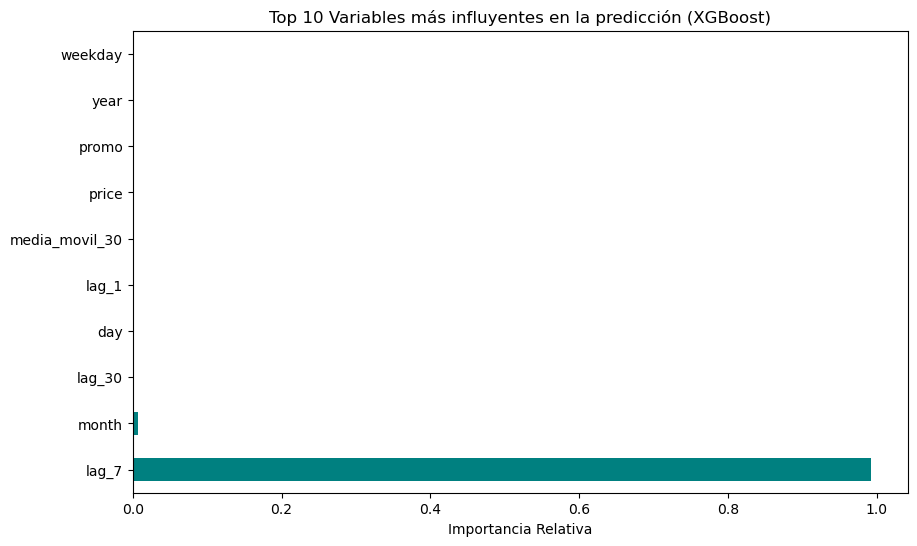

In [142]:
plt.figure(figsize=(10, 6))
# Asegúrate de usar el nombre de tu objeto modelo entrenado
feat_importances = pd.Series(modelo_xgb.feature_importances_, index=X_train.columns)
feat_importances.nlargest(10).plot(kind='barh', color='teal')
plt.title('Top 10 Variables más influyentes en la predicción (XGBoost)')
plt.xlabel('Importancia Relativa')
plt.show()

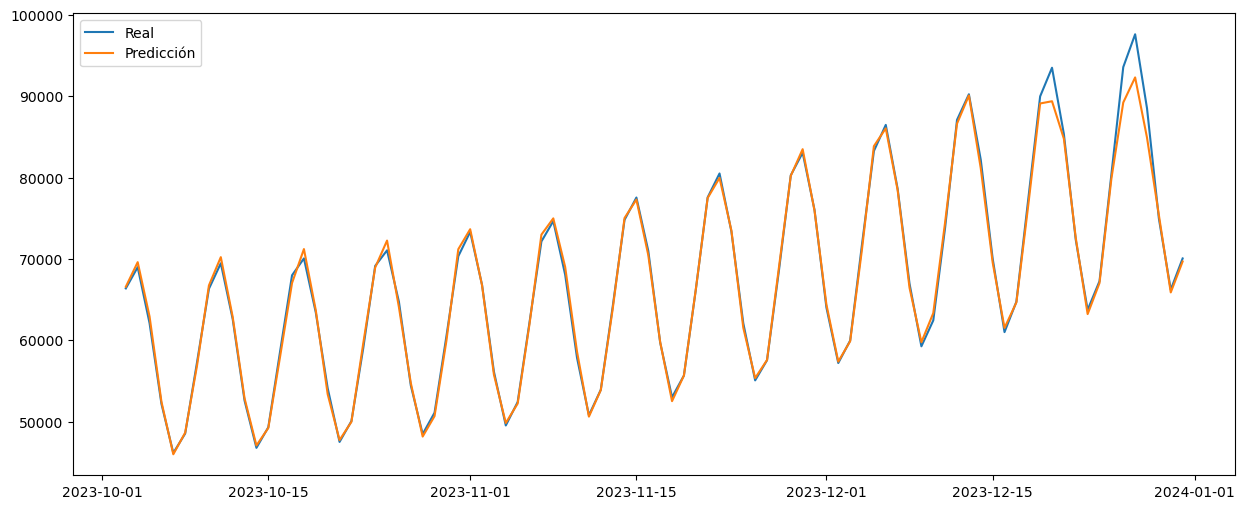

In [123]:
plt.figure(figsize=(15,6))

plt.plot(
    test["date"],
    y_test,
    label="Real"
)

plt.plot(
    test["date"],
    pred_xgb,
    label="Predicción"
)

plt.legend()

plt.show()

### Forecast futuro con XGBoost

In [124]:
# Última fecha disponible en el dataset
ultima_fecha = ventas_diarias["date"].max()

print(ultima_fecha)

2023-12-31 00:00:00


In [125]:
# Fechas futuras hasta diciembre de 2025

fechas_futuras = pd.date_range(
    start=ultima_fecha + pd.Timedelta(days=1),
    end="2025-12-31",
    freq="D"
)

print(f"Total días a pronosticar: {len(fechas_futuras)}")

Total días a pronosticar: 731


In [126]:
# Copia para ir agregando las predicciones

historico = ventas_diarias.copy()

predicciones = []

In [127]:
# ==========================================================
# GENERACIÓN DEL FORECAST FUTURO
# ==========================================================

for fecha in fechas_futuras:

    # Variables lag
    lag_1 = historico["sales"].iloc[-1]
    lag_7 = historico["sales"].iloc[-7]
    lag_30 = historico["sales"].iloc[-30]

    # Rolling feature
    media_movil_30 = historico["sales"].tail(30).mean()

    # Crear fila para predecir
    fila = pd.DataFrame({

        "promo": [historico["promo"].mean()],
        "price": [historico["price"].mean()],
        "rolling_mean_30": [media_movil_30],

        "year": [fecha.year],
        "month": [fecha.month],
        "day": [fecha.day],
        "weekday": [fecha.weekday()],
        "quarter": [fecha.quarter],

        "weekend": [1 if fecha.weekday() >= 5 else 0],

        "lag_1": [lag_1],
        "lag_7": [lag_7],
        "lag_30": [lag_30]

    })

    # Predicción
    pred = modelo_xgb.predict(fila)[0]

    predicciones.append(pred)

    # Agregar predicción al histórico
    nueva_fila = pd.DataFrame({
        "date": [fecha],
        "sales": [pred],
        "promo": [historico["promo"].mean()],
        "price": [historico["price"].mean()]
    })

    historico = pd.concat(
        [historico, nueva_fila],
        ignore_index=True
    )

In [145]:
forecast = pd.DataFrame({
    "date": fechas_futuras,
    "forecast_sales": predicciones
})

display(forecast)

,date,forecast_sales
0,2024-01-01,82923.0078
1,2024-01-02,96499.0781
2,2024-01-03,101181.0391
3,2024-01-04,91827.0469
4,2024-01-05,77341.3750
...,...,...
726,2025-12-27,64945.6484
727,2025-12-28,69340.7344
728,2025-12-29,78367.9453
729,2025-12-30,87257.8828


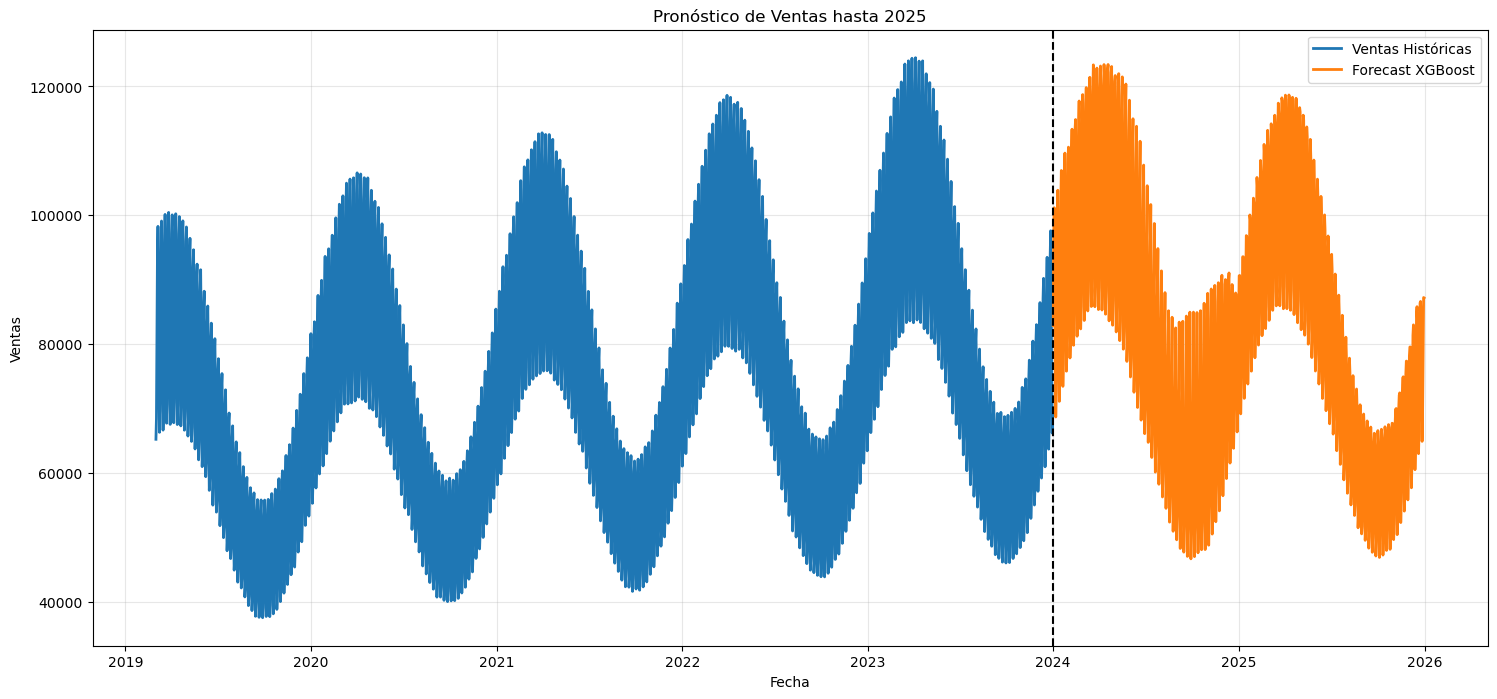

In [129]:
plt.figure(figsize=(18,8))

# Histórico
plt.plot(
    ventas_diarias["date"],
    ventas_diarias["sales"],
    label="Ventas Históricas",
    linewidth=2
)

# Forecast
plt.plot(
    forecast["date"],
    forecast["forecast_sales"],
    label="Forecast XGBoost",
    linewidth=2
)

# Línea divisoria
plt.axvline(
    ventas_diarias["date"].max(),
    color="black",
    linestyle="--"
)

plt.title("Pronóstico de Ventas hasta 2025")
plt.xlabel("Fecha")
plt.ylabel("Ventas")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [130]:
forecast["year"] = forecast["date"].dt.year

forecast.groupby("year")["forecast_sales"].sum()

year
2024   30618380.0000
2025   29386802.0000
Name: forecast_sales, dtype: float32

Una vez seleccionado XGBoost como modelo final, se generó un pronóstico recursivo hasta el año 2025. Para cada periodo futuro se utilizaron las predicciones previas para actualizar las variables lag y las medias móviles, permitiendo simular el comportamiento esperado de las ventas bajo las tendencias históricas observadas. Este enfoque facilita la planificación comercial, presupuestaria y operativa de largo plazo.